# IA Hybride et Apprentissage Automatique (L6SOIAAU)<br>
## TD 7 : Implémentation d'un réseau de neurones
### Exercices avec `scikit-learn`

Ljudmila PETKOVIC<br>
Licence « Sciences du langage » (L3)<br>
Sorbonne Université, UFR Sociologie et Informatique pour les Sciences Humaines<br>
20/03/2026

Ce cahier regroupe 10 exercices sur le jeu de données **Digits** et un classifieur **MLP**.


## Exercice 1 - Charger les données

Complétez le code suivant :

```python
from sklearn import datasets

data = datasets.________()
```


## Étape 1 - Charger les données

**Questions :**
1. Quel jeu de données est chargé ici ?


- jeu de données Digits  data = datasets.load_digits( )

  scikit-learn 内置的Digits 数据集
- dir(data)   # affiche les propriétés du jeu de données 'data'

  dir( )显示数据集 data 的所有属性 / 方法

In [ ]:
# Chargement des modules pour charger le dataset
from sklearn import datasets
data = datasets.________() # charger un dataset spécifique

### Solution 1


In [ ]:
from sklearn import datasets
import matplotlib.pyplot as plt  # pour visualiser

data = datasets.load_digits() # 答案：load_digits
data

{'data': array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]], shape=(1797, 64)),
 'target': array([0, 1, 2, ..., 8, 9, 8], shape=(1797,)),
 'frame': None,
 'feature_names': ['pixel_0_0',
  'pixel_0_1',
  'pixel_0_2',
  'pixel_0_3',
  'pixel_0_4',
  'pixel_0_5',
  'pixel_0_6',
  'pixel_0_7',
  'pixel_1_0',
  'pixel_1_1',
  'pixel_1_2',
  'pixel_1_3',
  'pixel_1_4',
  'pixel_1_5',
  'pixel_1_6',
  'pixel_1_7',
  'pixel_2_0',
  'pixel_2_1',
  'pixel_2_2',
  'pixel_2_3',
  'pixel_2_4',
  'pixel_2_5',
  'pixel_2_6',
  'pixel_2_7',
  'pixel_3_0',
  'pixel_3_1',
  'pixel_3_2',
  'pixel_3_3',
  'pixel_3_4',
  'pixel_3_5',
  'pixel_3_6',
  'pixel_3_7',
  'pixel_4_0',
  'pixel_4_1',
  'pixel_4_2',
  'pixel_4_3',
  'pixel_4_4',
  'pixel_4_5',
  'pixel_4_6',
  'pixel_4_7'

## Exercice 2 - Comprendre shape

On utilise l’instruction suivante :

```python
data.images.shape
```


## Étape 2 - Comprendre shape

**Questions :**
1. Que représente `data.images` ?
2. Que signifie `shape` ici ?


### Solution 2


In [ ]:
data.images.shape

(1797, 8, 8)

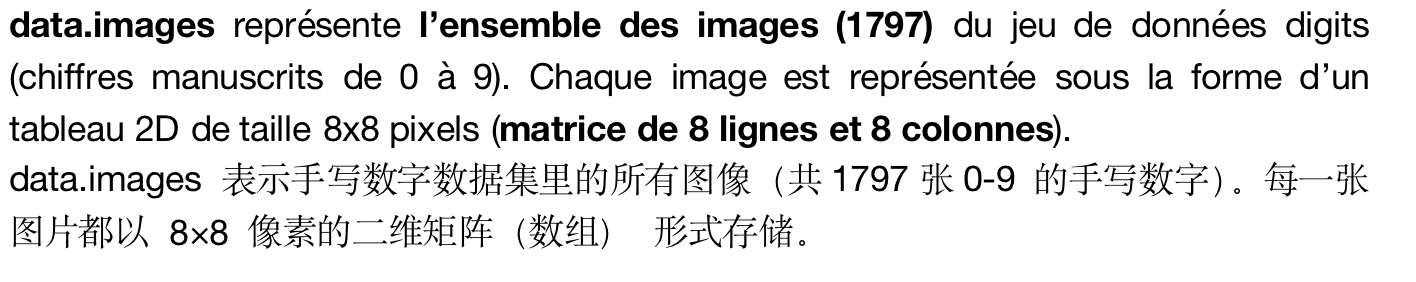

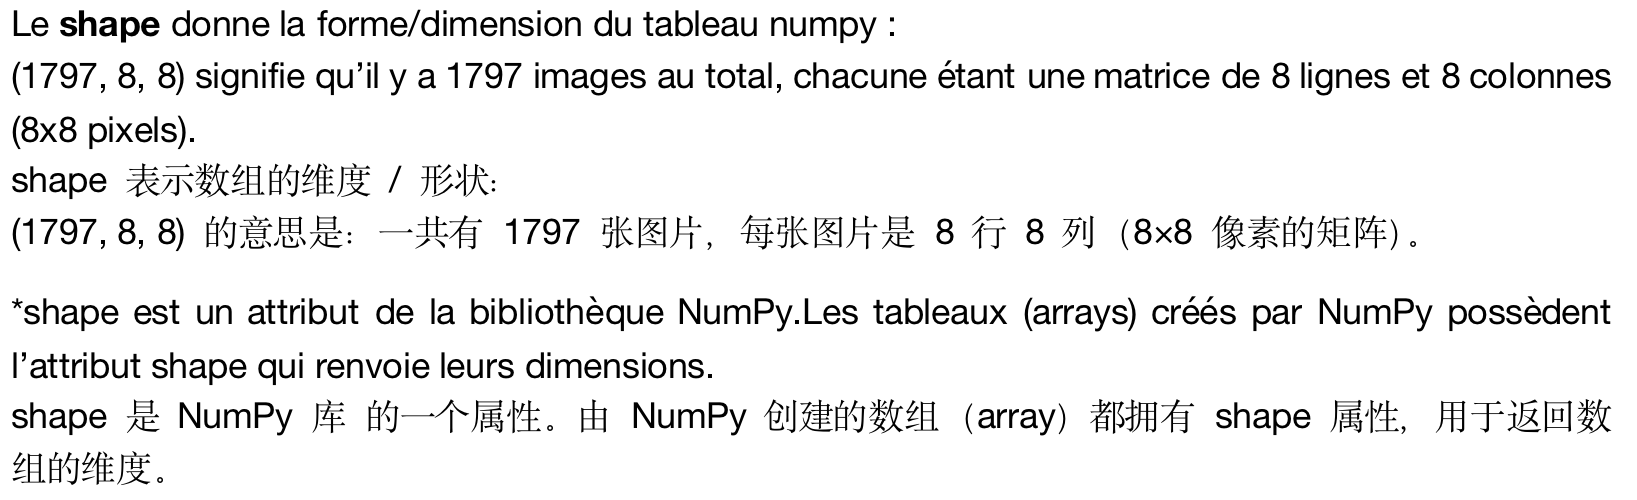

## Étape 3 - Afficher une image

**Questions :**
1. Que représente `data.images[0]` ?


In [ ]:
import matplotlib.pyplot as plt
plt.imshow(data.images[___], cmap='gray')
plt.show()

### Solution 3


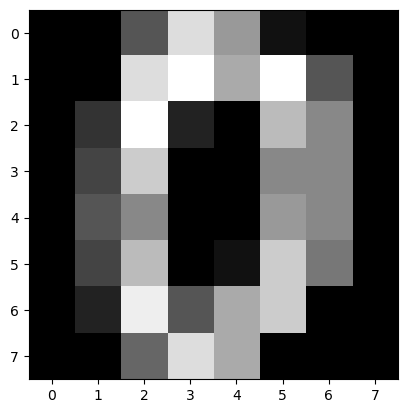

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(2, 2))
plt.imshow(data.images[0], cmap='gray')
plt.show()

- `data.images[0]` représente la première image du jeu de données.

  data.images[0] 表示数据集中的第一张图片。

## Exercice 4 - Entrées et sorties

On utilise :

```python
y = data.target
x = data.images.reshape((len(data.images), -1))
```


## Étape 4 - Entrées et sorties

**Questions :**
1. Que contient `y` ?
2. Pourquoi utilise-t-on `reshape(...)` ?
3. Que représente `x` ?


### Solution 4


In [ ]:
y = data.target
x = data.images.reshape((len(data.images), -1))
print('y shape =', y.shape)
print('x shape =', x.shape)

y shape = (1797,)
x shape = (1797, 64)


- `y` contient les étiquettes, c’est-à-dire le chiffre correct(la sortie attendue).

  y 包含正确的数字标签，是模型的目标输出。
- `reshape(...)` transforme chaque image de matrices 2D (8x8) en vecteurs 1D (64). Les réseaux de neurones prennent des vecteurs en entrée.

  使用 reshape 是为了把 8×8 的二维矩阵图片展平成 64 维的一维向量，神经网络只能接收向量输入。
- `x` représente les données d’entrée du modèle : ce sont les pixels des images sous forme de vecteurs.

  x 表示模型的输入数据（特征）：即向量化后的图片像素。

## Exercice 5 - Taille des données

On utilise :

```python
len(data.images)
len(data.target)
```


## Étape 5 -  Taille des données

**Questions :**
1. Pourquoi ces deux longueurs doivent-elles être égales ?


### Solution 5


In [ ]:
print(len(data.images))
print(len(data.target))

1797
1797


- Parce que chaque image possède une unique étiquette associée. Il faut autant d’images que de labels.

  因为每一张图片都对应一个标签，图片数量和标签数量必须一致。

## Exercice 6 - Séparer entraînement et test

Complétez le code suivant :

```python
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)
```


## Étape 6 - Séparer entraînement et test

**Questions :**
1. À quoi sert cette séparation ?
2. Que signifie `test_size = 0.2` ?


### Solution 6


In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print(x_train.shape)
print(x_test.shape)

(1437, 64)
(360, 64)


- Elle permet d’entraîner le modèle sur une partie des données et de l’évaluer sur des données nouvelles pour tester sa généralisation.

  用一部分数据训练模型，另一部分全新数据测试模型，评估泛化能力。


- `test_size=0.2` signifie que 20 % des données sont réservées au test, et 80% pour l’entraînement.

  20% 数据用作测试集，80% 用作训练集。


## Exercice 7 - Créer un modèle

On crée un classifieur :

```python
from sklearn.neural_network import MLPClassifier

mlp_classifier = MLPClassifier(hidden_layer_sizes=(10,), max_iter=300, random_state=42)
```


## Étape 7 - Créer un modèle

**Questions :**
1. Quel type de modèle crée-t-on ici ?
2. À quoi sert `hidden_layer_sizes=(10,)` ?


### Solution 7


In [ ]:
from sklearn.neural_network import MLPClassifier
mlp_classifier = MLPClassifier(hidden_layer_sizes=(10,),
                               max_iter=300,
                               random_state=42)
mlp_classifier

,hidden_layer_sizes,"(10,)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,300
,shuffle,True
,random_state,42


- On crée un `MLPClassifier`, c’est-à-dire un réseau de neurones simple pour la classification.

  我们创建一个MLP 分类器，即一个用于分类任务的简易神经网络。
- `hidden_layer_sizes=(10,)` signifie qu’il y a une couche cachée avec 10 neurones.

  定义了一个包含 10 个神经元的隐藏层。



## Exercice 8 - Entraîner et prédire

On utilise :

```python
mlp_classifier.fit(x_train, y_train)
predictions = mlp_classifier.predict(x_test)
```


## Étape 8 - Entraîner et prédire

**Questions :**
1. À quoi sert `fit(...)` ?
2. À quoi sert `predict(...)` ?
3. Quelle est la différence entre `y_test` et `predictions` ?


### Solution 8


In [ ]:
mlp_classifier.fit(x_train, y_train)
predictions = mlp_classifier.predict(x_test)
print(predictions[:10])
print(y_test[:10])

[6 9 3 7 2 1 5 2 5 3]
[6 9 3 7 2 1 5 2 5 2]


/opt/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


- `fit(...)` sert à **entraîner le modèle** sur les données d’entraînement.

  fit 函数的作用是用训练数据训练模型。
- `predict(...)` sert à **prédire les classes** sur de nouvelles données (le test).

  predict 函数的作用是对测试数据进行预测。  
- `y_test` contient les **vraies réponses**, `predictions` sont les **réponses prédites**.

  y_test 是正确答案，predictions 是模型给出的预测结果。


## Exercice 9 - Évaluer le modèle

On calcule :

```python
from sklearn.metrics import accuracy_score

accuracy_score(y_test, predictions)
```


## Étape 9 - Évaluer le modèle

**Questions :**
1. Que mesure `accuracy_score` ?


### Solution 9


In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, predictions)

0.9527777777777777

- `accuracy_score` mesure la proportion de bonnes prédictions.

  accuracy_score 衡量模型的总体准确率

## Étape 10 - Comparer une prédiction

**Questions :**
1. Que peut-on conclure si les deux valeurs sont identiques ?


### Solution 10


In [ ]:
i = 0
print('Prédiction :', predictions[i])
print('Vraie valeur :', y_test[i])

Prédiction : 6
Vraie valeur : 6


- Si les deux valeurs sont identiques, alors la prédiction est correcte pour cet exemple.

  如果两个值相同，说明模型预测正确。
